**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
M.C. Joan Manuel Raygoza Romero

# ICD - 20: Perceptrón y redes neuronales multicapa

Sesión 20 del curso. Diapositivas: [icd-20-perceptron-mlp.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-20-perceptron-mlp.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-20-perceptron-mlp.ipynb)

Entrenaremos una red para clasificar **datos tabulares** con dos variables. Usaremos
TensorFlow/Keras, scikit-learn y PyTorch sobre los mismos datos. Después modificaremos
una cosa a la vez para ver cómo cambia el resultado.

Ejecuta las celdas en orden en Jupyter o Colab. Si te falta alguna dependencia,
ejecuta lo siguiente en una celda y reinicia el kernel. Puedes realizar toda la práctica en CPU.

```python
%pip install numpy pandas matplotlib scikit-learn tensorflow torch
```

## 1. Preparar y visualizar los datos

Cada fila contiene `x1`, `x2` y una clase. La clase ideal es 1 si las variables
tienen signos opuestos (XOR). Invertimos aproximadamente el 6 % de las etiquetas
para introducir ruido.

Usamos 60 % de los datos para entrenar, 20 % para comparar modelos y 20 % para
la prueba final. El escalador se ajusta únicamente con entrenamiento.

In [1]:
import os

os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "2")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

SEMILLA = 42
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(SEMILLA)
datos = pd.DataFrame({
    "x1": rng.uniform(-2, 2, 1600),
    "x2": rng.uniform(-120, 120, 1600),
})
xor = (datos["x1"] > 0) ^ (datos["x2"] > 0)
datos["clase"] = (xor ^ (rng.random(len(datos)) < 0.06)).astype(int)
display(datos.head())

X = datos[["x1", "x2"]].to_numpy(dtype=np.float32)
y = datos["clase"].to_numpy()
X_des, X_prueba, y_des, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA,
)
X_ent, X_val_original, y_ent, y_val = train_test_split(
    X_des, y_des, test_size=0.25, stratify=y_des, random_state=SEMILLA,
)
escalador = StandardScaler().fit(X_ent)
X_ent = escalador.transform(X_ent)
X_val = escalador.transform(X_val_original)

,x1,x2,clase
0,1.095824,99.188444,0
1,-0.244486,-86.386703,0
2,1.434392,42.650067,0
3,0.789472,75.473730,0
4,-1.623291,-63.538467,0


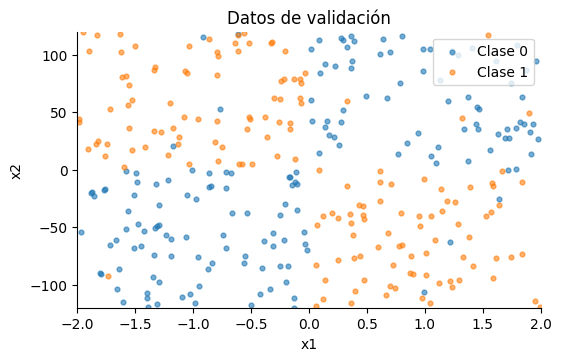

In [2]:
def dibujar_datos(ax, X, y):
    for clase, color in [(0, "tab:blue"), (1, "tab:orange")]:
        puntos = X[y == clase]
        ax.scatter(*puntos.T, s=12, alpha=0.6, color=color, label=f"Clase {clase}")
    ax.set(xlabel="x1", ylabel="x2", xlim=(-2, 2), ylim=(-120, 120))


fig, ax = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
dibujar_datos(ax, X_val_original, y_val)
ax.set_title("Datos de validación")
ax.legend()
plt.show()

## 2. Entrenar la primera red con TensorFlow/Keras

Partimos de **2 entradas → 16 neuronas → 16 neuronas → 1 salida**. ReLU es la
activación de las capas ocultas. La sigmoide de salida estima la probabilidad de la
clase 1. Adam ajusta los pesos para reducir la entropía cruzada binaria (BCE).

Un **lote** (*batch*) aporta los datos para una actualización. Una **época** recorre
todos los datos de entrenamiento. La **tasa de aprendizaje** controla el tamaño de
las actualizaciones. Observa dónde se indican esos tres valores en el código.

In [13]:
from tensorflow import keras

CAPAS = (16, 16)
LOTE = 32
EPOCAS = 40
TASA = 0.05


def entrenar_keras(capas=CAPAS, activacion="relu", perdida="binary_crossentropy",
                   lote=LOTE, epocas=EPOCAS, tasa=TASA, callbacks=()):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEMILLA)
    modelo = keras.Sequential([
        keras.Input(shape=(X_ent.shape[1],)),
        *[keras.layers.Dense(n, activation=activacion) for n in capas],
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa),
        loss=perdida,
        metrics=[keras.metrics.BinaryCrossentropy(name="bce")],
    )
    ajuste = modelo.fit(
        X_ent, y_ent.reshape(-1, 1),
        validation_data=(X_val, y_val.reshape(-1, 1)),
        batch_size=lote, epochs=epocas, callbacks=list(callbacks), verbose=0,
    )
    return modelo, ajuste.history


modelo_tf, hist_base = entrenar_keras()
print(f"Parámetros de la red: {modelo_tf.count_params()}")

Parámetros de la red: 337


## 3. Entrenar la misma red en otras bibliotecas

**scikit-learn.** `MLPClassifier` configura la arquitectura con `hidden_layer_sizes`.
Cada llamada a `partial_fit` recorre una época. El clasificador ya usa BCE para
este problema binario.

In [4]:
modelo_sk = MLPClassifier(
    hidden_layer_sizes=CAPAS, activation="relu", solver="adam",
    alpha=0, batch_size=LOTE, learning_rate_init=TASA,
    random_state=np.random.RandomState(SEMILLA),
)
for _ in range(EPOCAS):
    modelo_sk.partial_fit(X_ent, y_ent, classes=[0, 1])

**PyTorch.** Aquí escribimos el ciclo de entrenamiento. En cada lote calculamos la
pérdida, obtenemos los gradientes con `backward()` y actualizamos los pesos con
`step()`. La red devuelve *logits*. `BCEWithLogitsLoss` incorpora la sigmoide al
calcular la pérdida.

In [5]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEMILLA)
torch.set_num_threads(1)
datos_ent = TensorDataset(
    torch.from_numpy(X_ent),
    torch.from_numpy(y_ent).float().reshape(-1, 1),
)
lotes = DataLoader(datos_ent, batch_size=LOTE, shuffle=True)
modelo_pt = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 1),
)
perdida_pt = nn.BCEWithLogitsLoss()
adam_pt = torch.optim.Adam(modelo_pt.parameters(), lr=TASA)

for _ in range(EPOCAS):
    modelo_pt.train()
    for x_lote, y_lote in lotes:
        adam_pt.zero_grad()
        perdida = perdida_pt(modelo_pt(x_lote), y_lote)
        perdida.backward()
        adam_pt.step()

### Comparar las predicciones

La **exactitud** cuenta aciertos con un umbral de 0.5. La **BCE** también toma en
cuenta la confianza de la predicción. Las tres bibliotecas comparten los datos y
la arquitectura, y pueden inicializar los pesos y ordenar los lotes de forma distinta.

In [6]:
def metricas(y, p):
    return {"BCE": log_loss(y, p), "Exactitud": accuracy_score(y, p >= 0.5)}


modelo_pt.eval()
with torch.no_grad():
    p_pt = torch.sigmoid(modelo_pt(torch.from_numpy(X_val))).numpy().ravel()

probabilidades = {
    "TensorFlow/Keras": modelo_tf(X_val, training=False).numpy().ravel(),
    "scikit-learn": modelo_sk.predict_proba(X_val)[:, 1],
    "PyTorch": p_pt,
}
display(pd.DataFrame({
    nombre: metricas(y_val, p) for nombre, p in probabilidades.items()
}).T.round(3))

,BCE,Exactitud
TensorFlow/Keras,0.223,0.950
scikit-learn,0.237,0.938
PyTorch,0.230,0.941


## 4. Experimentos

### 4.1 ¿Qué aprende la red con una activación lineal?

Comparamos dos redes idénticas y cambiamos la activación de las capas ocultas.
El fondo muestra la probabilidad de la clase 1. La línea negra indica el umbral de 0.5.
**Antes de ejecutar**, dibuja cómo tendría que verse la frontera para separar los cuadrantes.

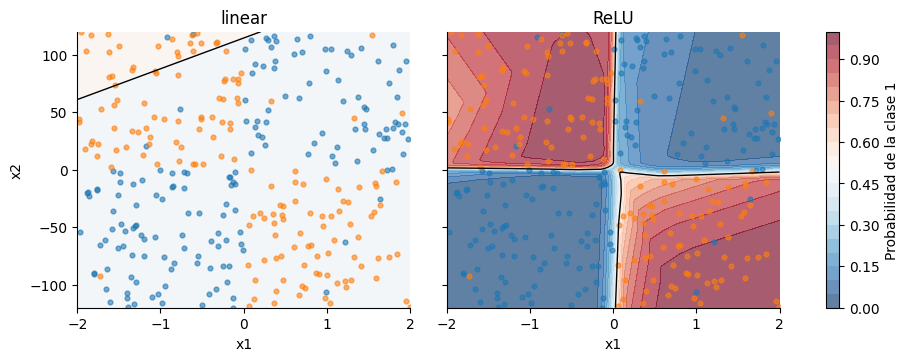

In [7]:
activacion_alternativa = "linear"
modelo_alternativo, _ = entrenar_keras(activacion=activacion_alternativa)
u, v = np.meshgrid(np.linspace(-2, 2, 150), np.linspace(-120, 120, 150))
rejilla = escalador.transform(np.column_stack([u.ravel(), v.ravel()]))

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True, layout="constrained")
for ax, (nombre, modelo) in zip(ejes, [(activacion_alternativa, modelo_alternativo), ("ReLU", modelo_tf)]):
    p = modelo(rejilla, training=False).numpy().reshape(u.shape)
    fondo = ax.contourf(u, v, p, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.65)
    if p.min() < 0.5 < p.max():
        ax.contour(u, v, p, levels=[0.5], colors="black", linewidths=1)
    dibujar_datos(ax, X_val_original, y_val)
    ax.set_title(nombre)
ejes[1].set_ylabel("")
fig.colorbar(fondo, ax=ejes, label="Probabilidad de la clase 1")
plt.show()

### 4.2 ¿Qué pasa al cambiar un solo parámetro?

En cada panel, la curva azul corresponde a la **misma red de referencia**.
Las otras curvas cambian solo el parámetro indicado. Para comparar las funciones
de pérdida, todas las curvas muestran **BCE de validación**, incluso si el modelo
se entrenó con error cuadrático medio (MSE) o error absoluto medio (MAE).

| Experimento | Referencia | Variantes |
|---|---|---|
| 1. Capas ocultas | 2 capas de 16 | 1, 3 y 4 capas de 16 |
| 2. Neuronas por capa | 16 por capa | 4, 8 y 32 por capa, con 2 capas |
| 3. Función de pérdida | BCE | MSE y MAE |
| 4. Tamaño de lote | 32 | 8, 128 y lote completo |
| 5. Épocas | 40 | 5 |
| 6. Tasa de aprendizaje | 0.05 | 0.0003, 0.005 y 0.2 |

En el panel de épocas marcamos la pérdida en la quinta época de la corrida de referencia.
Cada panel ajusta su escala vertical a sus curvas.

**Para explorar.** Compara la BCE en las épocas 5 y 40. ¿La variante que mejora antes
también termina mejor? En el panel de lotes, calcula cuántas actualizaciones por época
hace cada variante. Para probar otros valores, edita el diccionario `experimentos`.

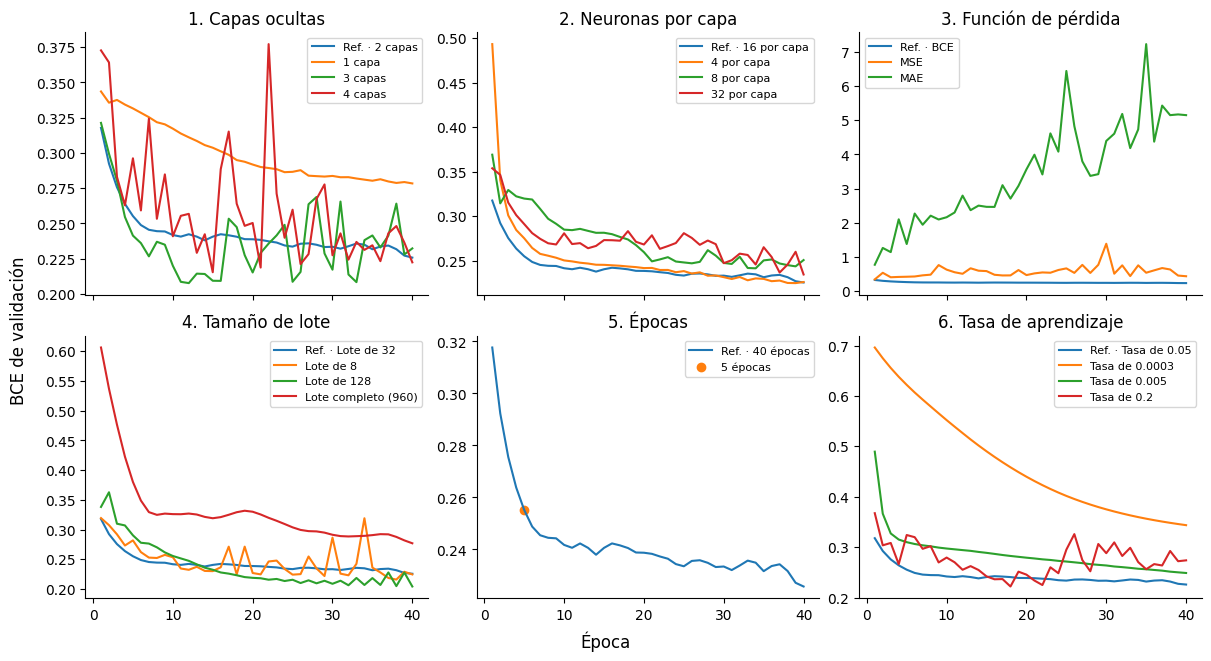

In [15]:
experimentos = {
    "1. Capas ocultas": (f"{len(CAPAS)} capas", [
        ("1 capa", {"capas": (16,)}),
        ("3 capas", {"capas": (16, 16, 16)}),
        ("4 capas", {"capas": (16, 16, 16, 16)}),
    ]),
    "2. Neuronas por capa": (f"{CAPAS[0]} por capa", [
        ("4 por capa", {"capas": (4, 4)}),
        ("8 por capa", {"capas": (8, 8)}),
        ("32 por capa", {"capas": (32, 32)}),
    ]),
    "3. Función de pérdida": ("BCE", [
        ("MSE", {"perdida": "mean_squared_error"}),
        ("MAE", {"perdida": "mean_absolute_error"}),
    ]),
    "4. Tamaño de lote": (f"Lote de {LOTE}", [
        ("Lote de 8", {"lote": 8}),
        ("Lote de 128", {"lote": 128}),
        (f"Lote completo ({len(y_ent)})", {"lote": len(y_ent)}),
    ]),
    "5. Épocas": (f"{EPOCAS} épocas", [
        ("5 épocas", {"epocas": 5}),
    ]),
    "6. Tasa de aprendizaje": (f"Tasa de {TASA:g}", [
        ("Tasa de 0.0003", {"tasa": 0.0003}),
        ("Tasa de 0.005", {"tasa": 0.005}),
        ("Tasa de 0.2", {"tasa": 0.2}),
    ]),
}

base = hist_base["val_bce"]
fig, ejes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True,
                         layout="constrained")
for ax, (titulo, (referencia, variantes)) in zip(ejes.flat, experimentos.items()):
    ax.plot(range(1, len(base) + 1), base, label=f"Ref. · {referencia}", color="C0")
    for i, (etiqueta, cambios) in enumerate(variantes, start=1):
        if "epocas" in cambios and cambios["epocas"] <= len(base):
            epoca = cambios["epocas"]
            ax.scatter(epoca, base[epoca - 1], color=f"C{i}", label=etiqueta)
        else:
            _, historial = entrenar_keras(**cambios)
            bce = historial["val_bce"]
            ax.plot(range(1, len(bce) + 1), bce, color=f"C{i}", label=etiqueta)
    ax.set_title(titulo)
    ax.legend(fontsize=8)
fig.supxlabel("Época")
fig.supylabel("BCE de validación")
plt.show()

## 5. Ajustar la tasa y decidir cuándo parar

Repetimos el entrenamiento con un máximo de 80 épocas. Una variante reduce la
tasa a la mitad cada 15 épocas. La otra mantiene la tasa fija y aplica **parada
temprana**. Si pasan cinco épocas sin mejorar la BCE de validación, recupera
los pesos de la mejor época observada.

La línea vertical marca cuándo se detuvo esa variante. El punto indica qué
época recuperó. Compara la pérdida en esos dos momentos.

Épocas ejecutadas: 19 de 80
Época restaurada: 14


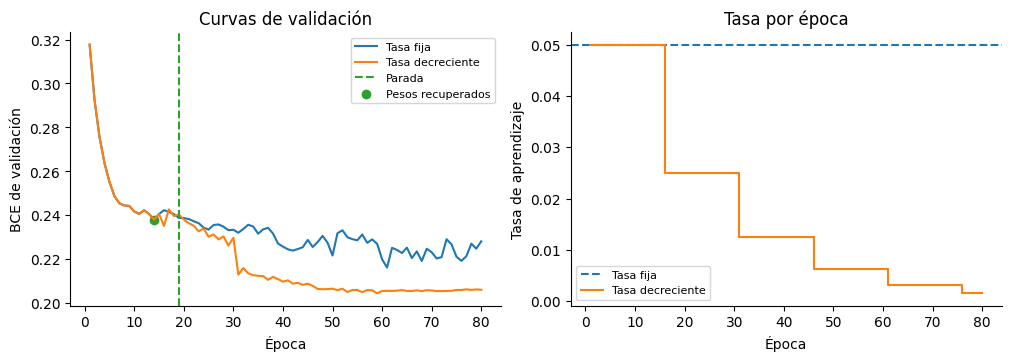

In [14]:
MAX_EPOCAS = 80

plan = keras.callbacks.LearningRateScheduler(
    lambda epoca, tasa: TASA * 0.5 ** (epoca // 15)
)
parada = keras.callbacks.EarlyStopping(
    monitor="val_bce", mode="min", patience=5, restore_best_weights=True,
)

modelo_fijo, fijo = entrenar_keras(epocas=MAX_EPOCAS)
modelo_plan, reducido = entrenar_keras(epocas=MAX_EPOCAS, callbacks=[plan])
modelo_parada, corto = entrenar_keras(epocas=MAX_EPOCAS, callbacks=[parada])

mejor = int(np.argmin(corto["val_bce"]))
print(f"Épocas ejecutadas: {len(corto['val_bce'])} de {MAX_EPOCAS}")
print(f"Época restaurada: {mejor + 1}")

epocas = np.arange(1, MAX_EPOCAS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
ax1.plot(epocas, fijo["val_bce"], label="Tasa fija")
ax1.plot(epocas, reducido["val_bce"], label="Tasa decreciente")
ax1.axvline(len(corto["val_bce"]), linestyle="--", color="tab:green", label="Parada")
ax1.scatter(mejor + 1, corto["val_bce"][mejor], color="tab:green", label="Pesos recuperados")
ax1.set(xlabel="Época", ylabel="BCE de validación", title="Curvas de validación")
ax1.legend(fontsize=8)

ax2.axhline(TASA, linestyle="--", label="Tasa fija")
ax2.step(epocas, reducido["learning_rate"], where="post",
         color="tab:orange", label="Tasa decreciente")
ax2.set(xlabel="Época", ylabel="Tasa de aprendizaje", title="Tasa por época")
ax2.legend(fontsize=8)
plt.show()

## 6. Evaluar en el conjunto de prueba

Elegimos entre los tres modelos de la sección 5 por su BCE de validación. Después
evaluamos el modelo elegido con los datos reservados. La matriz muestra cuántos
ejemplos de cada clase se clasificaron bien y cuántos se confundieron.

Modelo elegido: Tasa fija


,BCE,Exactitud
Prueba,0.309,0.928


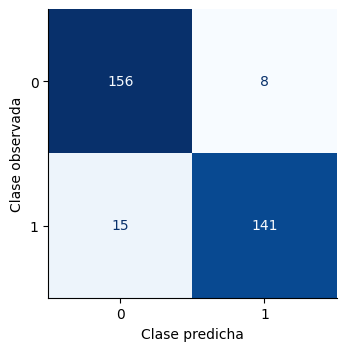

In [10]:
candidatos = {
    "Tasa fija": modelo_fijo,
    "Tasa decreciente": modelo_plan,
    "Parada temprana": modelo_parada,
}
elegido = min(candidatos, key=lambda nombre: log_loss(
    y_val, candidatos[nombre](X_val, training=False).numpy().ravel()
))
p_prueba = candidatos[elegido](escalador.transform(X_prueba), training=False).numpy().ravel()

print(f"Modelo elegido: {elegido}")
display(pd.DataFrame([metricas(y_prueba, p_prueba)], index=["Prueba"]).round(3))

fig, ax = plt.subplots(figsize=(4, 3.4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(
    y_prueba, p_prueba >= 0.5, labels=[0, 1], cmap="Blues", colorbar=False, ax=ax,
)
ax.set(xlabel="Clase predicha", ylabel="Clase observada")
plt.show()

### 7. ¿Cómo se ve el sobreajuste?

En este ejemplo entrenamos una red de dos capas ocultas de 128 neuronas con solo
64 observaciones. Así podemos observar qué ocurre cuando una red tiene mucha
capacidad y pocos datos para aprender.

Al principio, la pérdida de entrenamiento y la de validación disminuyen. Después
de unas cuantas épocas, la pérdida de entrenamiento sigue bajando, mientras que
la de validación empieza a subir. Esta divergencia es la señal de **sobreajuste**:
la red se ajusta mejor a los ejemplos de entrenamiento, pero sus predicciones
empeoran en los datos de validación.

La línea punteada marca la época con menor pérdida de validación. En la corrida
de referencia fue la **época 7**.

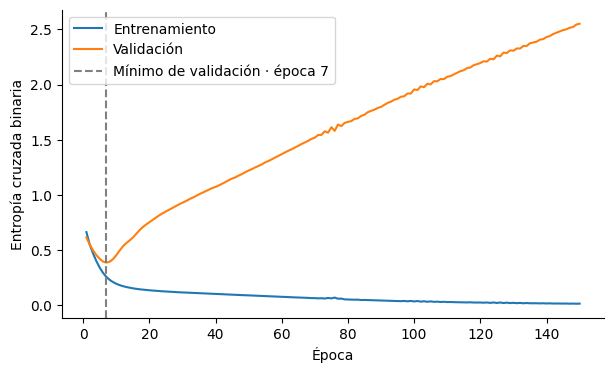

In [18]:
keras.utils.set_random_seed(42)
idx = np.random.default_rng(42).choice(len(y_ent), size=64, replace=False)

modelo_demo = keras.Sequential([
    keras.Input(shape=(X_ent.shape[1],)),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
modelo_demo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
)

hist = modelo_demo.fit(
    X_ent[idx], y_ent[idx],
    validation_data=(X_val, y_val),
    epochs=150, batch_size=16, verbose=0,
).history

epocas = range(1, len(hist["loss"]) + 1)
mejor = np.argmin(hist["val_loss"]) + 1

plt.figure(figsize=(7, 4))
plt.plot(epocas, hist["loss"], label="Entrenamiento")
plt.plot(epocas, hist["val_loss"], label="Validación")
plt.axvline(mejor, color="gray", linestyle="--",
            label=f"Mínimo de validación · época {mejor}")
plt.xlabel("Época")
plt.ylabel("Entropía cruzada binaria")
plt.legend()
plt.show()

## 8. Actividad para experimentar

Modifica **una cosa a la vez** y registra qué cambió en la gráfica de validación.

1. **Activación.** Cambia `activacion_alternativa` a `"tanh"` en la sección 4.1. ¿Qué forma toma la frontera?
2. **Arquitectura.** Cambia las capas a `(16, 16, 16)` o el ancho a `(32, 32)`. ¿Qué comparación modifica solo la profundidad?
3. **Pérdida.** Calcula BCE y MSE para $y=1$ con $p=0.6$ y $p=0.9$. ¿Por qué la exactitud es igual en los dos casos?
4. **Lotes y épocas.** Divide 960 filas en lotes de 32 y 128, redondeando hacia arriba. ¿Cuántas épocas con lote de 128 aproximan las actualizaciones de 5 épocas con lote de 32?
5. **Tasa y parada.** Prueba una tasa de `0.1` y describe la curva. Después cambia `patience` de 5 a 3 en la sección 5. ¿Se recuperan los pesos de la misma época?
6. **Reproducibilidad.** En la función de Keras cambia solo la semilla del modelo y repite una comparación. ¿Se mantiene la conclusión con la misma partición?

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de ChatGPT 6.1 Sol High (OpenAI) para estructurar el contenido a partir de las diapositivas de la sesión y redactar el texto explicativo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.